# 5. Target anyon-Hubbard Hamiltonian and energy gaps

**Thesis:** Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona (2026). [Read the thesis](https://hdl.handle.net/2445/231684).

**Reading guide:** Sections 1.2–1.3, pp. 7–8; Appendix C, pp. 47–51; Figures 8–9. Page numbers below are the printed thesis pages. Equations retain the thesis notation and numbering; an extract from a longer equation is identified as an extract.

**Evidence:** the physics text describes the theoretical model and numerical calculations reported in the thesis. It does not add experimental results or new derivations. Calculation cells come from the original uploaded scripts at commit `22959963191fcbc4d283ec4b272b506ad6dd979b`. Short setup cells only handle notebook execution and display.

Read each explanation, then run its code cell. Source discrepancies and notebook adaptations are labelled explicitly.

**Notebook setup / execution control:** Imports used by the scripts; locate the repository data directory and display plots inline.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
from timeit import default_timer as timer
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'scripts').is_dir() and (p / 'data').is_dir())
DATA = ROOT / 'data'

## 1. Hamiltonian and local occupation operators

**Thesis source:** Sections 1.2–1.3, pp. 7–8, Eqs. (6)–(7); Appendix C, p. 50. Explanations below paraphrase this passage.

The bosonic form of the target Hamiltonian is
$$H=-J\sum_j\left(b_j^\dagger e^{i\phi n_j}b_{j+1}+\mathrm{H.c.}\right)
+\frac{U}{2}\sum_j n_j(n_j-1).\tag{6}$$
$J$ is the tunnelling amplitude, $U$ the on-site interaction, and $\phi$ the statistical angle. The truncated operators are
$$b=|0\rangle\langle1|+\sqrt2|1\rangle\langle2|,\qquad
n=|1\rangle\langle1|+2|2\rangle\langle2|,\qquad b^3=0.\tag{7}$$
Appendix C uses open boundaries, $U=1$, and five lowest eigenvalues at each point of the saved ten-site grid. This is the target-model calculation; Notebook 01 covers the effective Rydberg Hamiltonian.

**Notebook setup / execution control:** Import the sparse solver and operator wrapper used in sweepGapsMulti.py.

In [2]:
from scipy.sparse.linalg import LinearOperator, eigsh

**Code source:** [`sweepGapsMulti.py`, lines 34–51](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/sweepGapsMulti.py#L34-L51).

**Notebook changes:** Set Nsites=4 only for the small live demonstration. The original ten-site results are loaded separately below. Other solver and operator settings are unchanged.

In [3]:
Nsites = 4                                 # lattice sites (dim = 3**N)
usePBC = False                              # open chain, as in the notes
numval = 5                                  # eigenvalues per grid point
U = 1.0                                     # energy unit
thetas = np.linspace(0.0, np.pi, 21)        # statistical angle
ratios = np.linspace(0.05, 1.0, 21)         # J/U ratio

# Lanczos controls. Near-degenerate low-lying levels (small J/U) converge
# slowly with the default Krylov subspace, so enlarge it; tol=1e-8 is far
# below the resolution of the plots.
ncv = 40
tol = 1e-8

# Local operators on the truncated space {|0>,|1>,|2>}, d = 3
d = 3
b = np.diag(np.sqrt(np.arange(1, d)), k=1)
bdag = b.conj().T
n_op = bdag @ b

## 2. On-site interaction

**Thesis source:** Appendix C, p. 50. Explanations below paraphrase this passage.

Appendix C precomputes the interaction as a diagonal vector, adding $U$ for a doubly occupied site. It keeps this contribution separate from the hopping bonds so every site is counted once.

**Code source:** [`sweepGapsMulti.py`, lines 54–58](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/sweepGapsMulti.py#L54-L58).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [4]:
u_site = (U / 2) * np.arange(d) * (np.arange(d) - 1)
Udiag = np.zeros(d**Nsites)
for k in range(Nsites):
  Udiag += np.kron(np.ones(d**k),
                   np.kron(u_site, np.ones(d**(Nsites - 1 - k))))

## 3. Matrix-free application of the Hamiltonian

**Thesis source:** Appendix C, pp. 49–50, Eq. (100). Explanations below paraphrase this passage.

Appendix C represents the Hamiltonian through its action on a state vector, avoiding storage of the complete matrix. The two-site hopping operator is
$$h=-J\left[(b^\dagger e^{i\phi n})\otimes b+(e^{-i\phi n}b)\otimes b^\dagger\right].\tag{100}$$
The state is reshaped and contracted with this operator one bond at a time. The thesis specifies complex states and a complex Hermitian bond operator.

**ED code attribution:** the uploaded `doApplyHam.py` adapts Glen Evenbly's [Tensors.net exact-diagonalization example](https://www.tensors.net/exact-diagonalization). Its original credit is retained in the next cell.

**Code source:** [`doApplyHam.py`, lines 1–43](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/doApplyHam.py#L1-L43).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [5]:
# doApplyHam.py
# ---------------------------------------------------------------------
# Routine used in the implementation of exact diagonalization.
#
# Adapted from Glen Evenbly (c) for www.tensors.net, (v1.2) - last
# modified 6/2019. Modified for complex Hamiltonians (the anyon-Hubbard
# density-dependent hopping phase e^{i*theta*n_j} makes hloc complex
# Hermitian), and works for arbitrary local dimension d.

import numpy as np


def doApplyHam(psiIn: np.ndarray,
               hloc: np.ndarray,
               N: int,
               usePBC: bool):
  """
  Applies local Hamiltonian, given as sum of nearest neighbor terms, to
  an input quantum state.
  Args:
    psiIn: vector of length d**N describing the quantum state.
    hloc: array of ndim=4 describing the nearest neighbor coupling.
    N: the number of lattice sites.
    usePBC: sets whether to include periodic boundary term.
  Returns:
    np.ndarray: state psi after application of the Hamiltonian.
  """
  d = hloc.shape[0]
  psiOut = np.zeros(psiIn.size, dtype=np.result_type(psiIn, hloc))
  for k in range(N - 1):
    # apply local Hamiltonian terms to sites [k,k+1]
    psiOut += np.tensordot(hloc.reshape(d**2, d**2),
                           psiIn.reshape(d**k, d**2, d**(N - 2 - k)),
                           axes=[[1], [1]]).transpose(1, 0, 2).reshape(d**N)

  if usePBC:
    # apply periodic term
    psiOut += np.tensordot(hloc.reshape(d, d, d, d),
                           psiIn.reshape(d, d**(N - 2), d),
                           axes=[[2, 3], [2, 0]]
                           ).transpose(1, 2, 0).reshape(d**N)

  return psiOut

## 4. Calculate the lowest eigenvalues

**Thesis source:** Appendix C, p. 50. Explanations below paraphrase this passage.

The thesis passes the Hamiltonian action to `scipy.sparse.linalg.eigsh`, asking for the algebraically smallest eigenvalues. The uploaded function uses `ncv=40`, tolerance $10^{-8}$, and a fixed starting-vector seed. The live cell below calls this original function at one four-site point; it is a demonstration, not a replacement for the archived sweep.

**Code source:** [`sweepGapsMulti.py`, lines 61–73](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/sweepGapsMulti.py#L61-L73).

**Notebook changes:** Copied from the original script; calculation unchanged.

In [6]:
def lowest_levels(J, theta):
  """Lowest 'numval' eigenvalues of H(J, U, theta) via Lanczos."""
  phase = np.diag(np.exp(1j * theta * np.diag(n_op)))
  hloc = (-J * (np.kron(bdag @ phase, b)
                + np.kron(phase.conj().T @ b, bdag))).reshape(d, d, d, d)
  H = LinearOperator((d**Nsites, d**Nsites),
                     matvec=lambda v: doApplyHam(v, hloc, Nsites, usePBC)
                     + Udiag * v,
                     dtype=np.complex128)
  # fixed starting vector so the sweep is reproducible run to run
  v0 = np.random.default_rng(1234).standard_normal(d**Nsites)
  return np.sort(eigsh(H, k=numval, which='SA', return_eigenvectors=False,
                       ncv=ncv, tol=tol, v0=v0))

**Notebook setup / execution control:** Call the original solver once at a labelled demonstration point. The 441-point ten-site sweep is not launched by Run All.

In [7]:
J_DEMO, PHI_DEMO = 0.3, np.pi / 2
print('Four-site demonstration, J/U =', J_DEMO / U, 'phi =', PHI_DEMO)
print('Lowest eigenvalues:', lowest_levels(J_DEMO, PHI_DEMO))

Four-site demonstration, J/U = 0.3 phi = 1.5707963267948966
Lowest eigenvalues: [-0.84278057 -0.7766791  -0.75745954 -0.6204282  -0.4854102 ]


## 5. Plot the archived ten-site sweep

**Thesis source:** Appendix C, pp. 50–51, Figures 8–9. Explanations below paraphrase this passage.

Appendix C reports a $21\times21$ grid in $J/U$ and $\phi\in[0,\pi]$, with five levels at every point. Figure 8 plots the differences $E_k-E_0$; Figure 9 plots consecutive level spacings.

The thesis explicitly states that the calculation uses the full occupation space without a chemical potential. These differences are global spacings over all particle-number sectors. A calculation at fixed filling would require restriction to one sector.

**Code reading:** the original `plot_all` loads the saved arrays and calculates those differences. The notebook displays each of its seven figures inline. No new gap definition or additional extrapolation is introduced.

**Notebook setup / execution control:** Standard path module and the original plotting script’s symbol dictionary.

In [8]:
import os
SYMBOLS = {'theta': r'\theta', 'phi': r'\phi'}

**Code source:** [`replotGapsMulti.py`, lines 27–42](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/replotGapsMulti.py#L27-L42).

**Notebook changes:** Inline display replaces file export. Nearest-cell shading shows the computed grid without interpolating it. Use L for site count to distinguish it from particle number; gap values are unchanged.

In [9]:
def _plot_one(ratios, thetas, diff, label, fname, Nsites, bc, sym):
  """Render a single gap heat map to its own figure file."""
  fig, ax = plt.subplots(figsize=(7, 5.2))
  mesh = ax.pcolormesh(ratios, thetas, diff.T, cmap='inferno',
                       shading='nearest')
  cbar = fig.colorbar(mesh, ax=ax)
  cbar.set_label(r'$(%s)/U$' % label)
  ax.set_xlabel(r'$J/U$')
  ax.set_ylabel(r'Statistical phase $%s$' % sym)
  ax.set_yticks(np.pi * np.array([0, 0.25, 0.5, 0.75, 1.0]))
  ax.set_yticklabels([r'$0$', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
  ax.set_title(r'$%s$, $L = %d$ sites (%s)' % (label, Nsites, bc))
  fig.tight_layout()
  display(fig)
  plt.close(fig)

**Code source:** [`replotGapsMulti.py`, lines 45–71](https://github.com/adicos0/linear-anyon-rydberg-thesis-plots/blob/22959963191fcbc4d283ec4b272b506ad6dd979b/scripts/replotGapsMulti.py#L45-L71).

**Notebook changes:** Preserve the original loading and gap-difference calculations; disable pickle and omit directory creation because figures are displayed inline.

In [10]:
def plot_all(npzfile=None, Nsites=None, symbol='theta', outdir='.'):
  if npzfile is None:
    npzfile = 'anyonHubbardGapsMulti_N%d.npz' % Nsites
  sym = SYMBOLS[symbol]
  dat = np.load(npzfile, allow_pickle=False)
  thetas, ratios = dat['thetas'], dat['ratios']
  energies = dat['energies']            # shape (n_ratios, n_thetas, nlev)
  L, usePBC = int(dat['Nsites']), bool(dat['usePBC'])
  nlev = energies.shape[2]
  bc = 'PBC' if usePBC else 'OBC'


  def path(name):
    return os.path.join(outdir, name)

  # Gaps measured from the ground state: E_k - E_0
  for k in range(1, nlev):
    _plot_one(ratios, thetas, energies[:, :, k] - energies[:, :, 0],
              'E_%d - E_0' % k,
              path('anyonHubbardGap_N%d_E%d-E0.png' % (L, k)), L, bc, sym)

  # Consecutive level spacings: E_{k+1} - E_k
  for k in range(1, nlev - 1):
    _plot_one(ratios, thetas, energies[:, :, k + 1] - energies[:, :, k],
              'E_%d - E_%d' % (k + 1, k),
              path('anyonHubbardGap_N%d_E%d-E%d.png' % (L, k + 1, k)),
              L, bc, sym)

**Notebook setup / execution control:** Use the repository’s archived sweep and the thesis symbol phi.

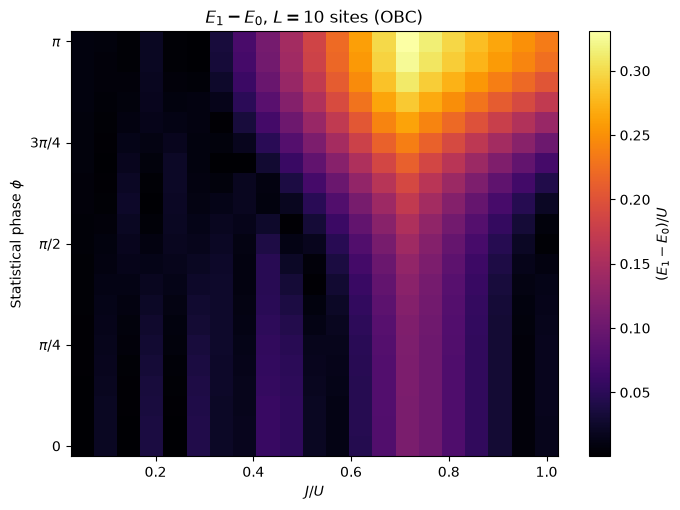

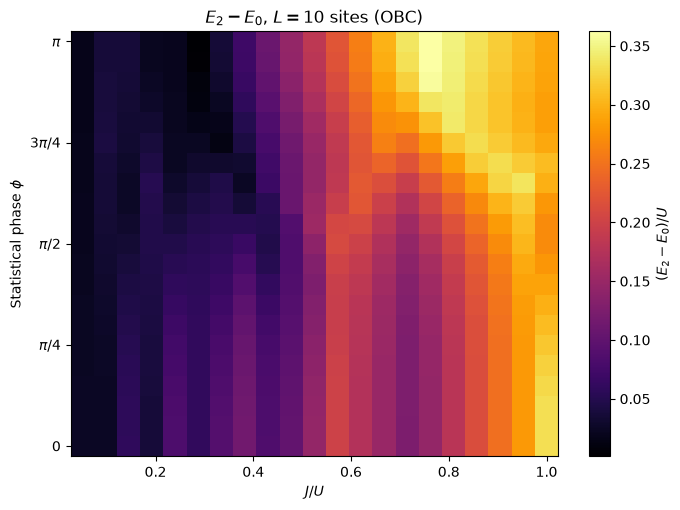

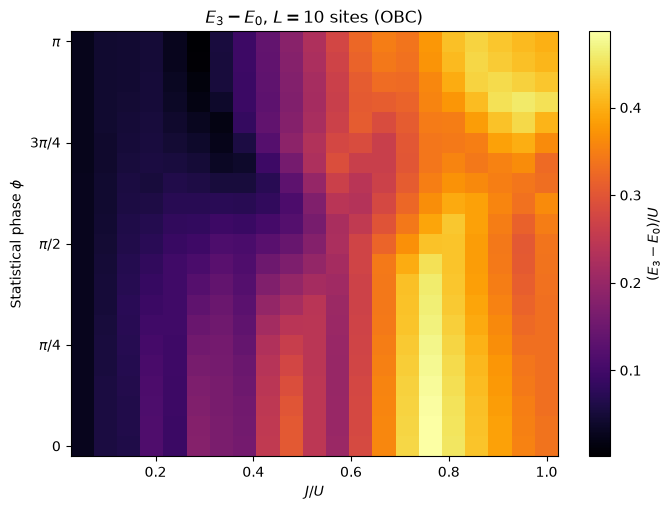

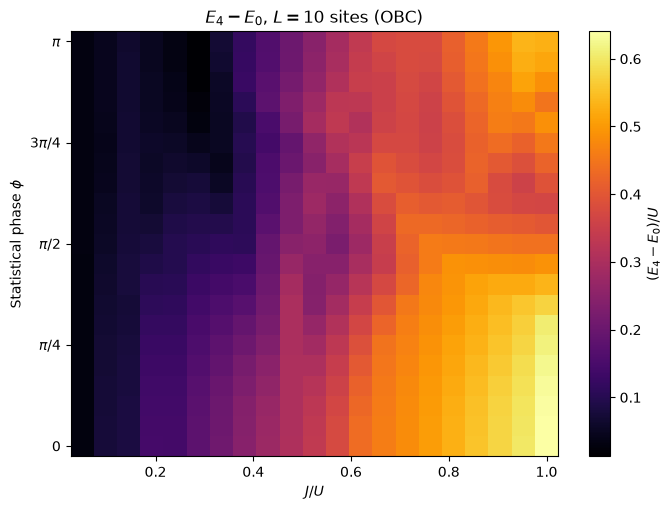

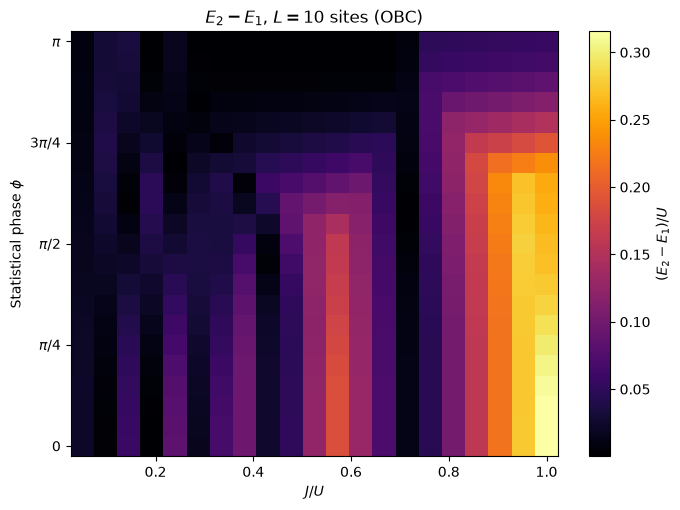

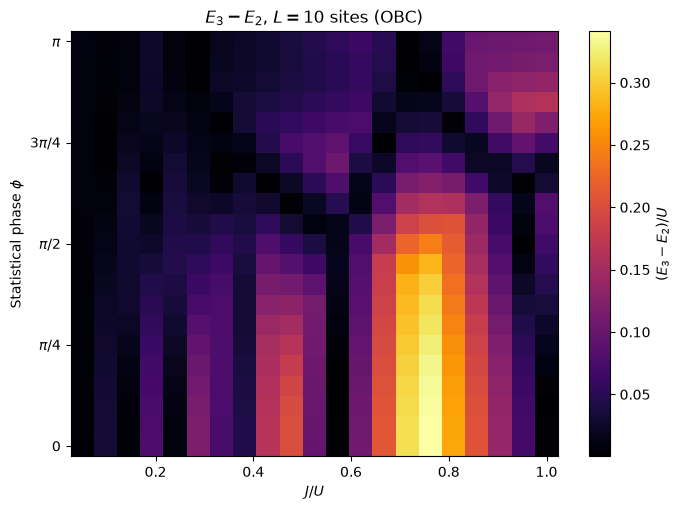

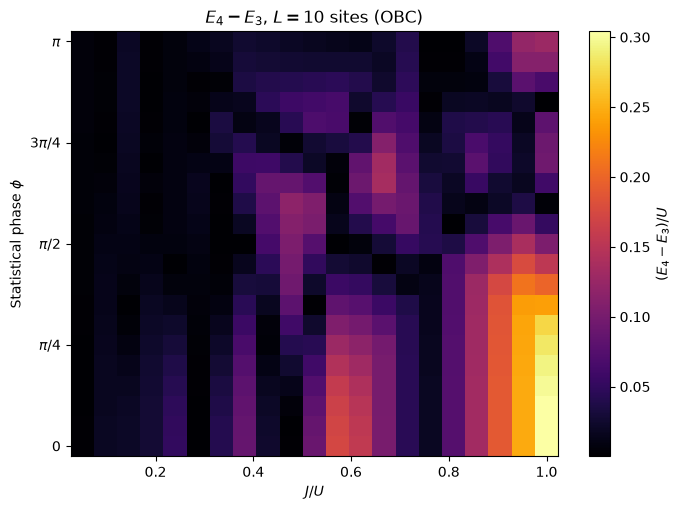

In [11]:
plot_all(str(DATA / 'anyonHubbardGapsMulti_N10.npz'), symbol='phi')

## Source and reproduction record

The original scripts and saved data are unchanged. See [SOURCE_MAP.md](SOURCE_MAP.md) for the thesis-to-code map and [VALIDATION.md](VALIDATION.md) for the checks performed on this revision.